# Risk Management - Group Work Project 3: Forecasting Oil Price Regimes with HMM Discretization and Bayesian Networks

Notes: PRODUCTION_COST_CAD and GLOBAL_OIL_SUPPLY are synthetic placeholder series. The 0% validation/test error flagged by the notebook's own guardrail is a likely leakage artifact and should not be read as real predictive accuracy.

# Step 4

## 0. Install and import

In [ ]:
!pip -q install pgmpy==1.1.2 hmmlearn==0.3.3 yfinance==0.2.* pandas-datareader networkx matplotlib seaborn 2>&1 | tail -2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 15.0 MB/s eta 0:00:00


In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.collections import LineCollection
import seaborn as sns
import networkx as nx
from hmmlearn import hmm
from pgmpy.estimators import HillClimbSearch, K2, BIC, BDeu
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.models import DiscreteBayesianNetwork
import yfinance as yf
import pandas_datareader.data as pdr
from sklearn.metrics import (confusion_matrix,
                             precision_recall_fscore_support,
                             accuracy_score)

SEED = 42
np.random.seed(SEED)
sns.set_style('whitegrid')
print('Environment ready.')

Environment ready.


## 1. Data acquisition (monthly)

In [ ]:
START = '2000-01-01'
END   = '2026-04-01'

yf_tickers = {
    'OIL_PRICE_WTI':'CL=F', 'SP500_INDEX':'^GSPC', 'USD_INDEX':'DX-Y.NYB',
    'VIX':'^VIX', 'RIG_COUNT_PROXY':'^IRX', 'ENERGY_SECTOR_XLE':'XLE',
    'OIL_EXPLORATION_XOP':'XOP', 'US_OIL_FUND_USO':'USO',
}
yf_df = pd.DataFrame()
for name, tkr in yf_tickers.items():
    try:
        s = yf.download(tkr, start=START, end=END, progress=False, auto_adjust=True)['Close']
        if isinstance(s, pd.DataFrame): s = s.iloc[:, 0]
        s.name = name
        yf_df = pd.concat([yf_df, s], axis=1)
    except Exception as e:
        print(f' ! {name} ({tkr}) failed: {e}')

fred_series = {'GDP_US':'GDP', 'IND_PROD_US':'INDPRO', 'CPI_US':'CPIAUCSL'}
fred_df = pd.DataFrame()
for name, code_ in fred_series.items():
    try:
        s = pdr.DataReader(code_, 'fred', START, END).iloc[:, 0]
        s.name = name
        fred_df = pd.concat([fred_df, s], axis=1)
    except Exception as e:
        print(f' ! {name} ({code_}) failed: {e}')

yf_df.index = pd.to_datetime(yf_df.index)
fred_df.index = pd.to_datetime(fred_df.index)
yf_m   = yf_df.resample('ME').mean()
fred_m = fred_df.resample('ME').mean()
data_m = pd.concat([yf_m, fred_m], axis=1)
data_m['GDP_US'] = data_m['GDP_US'].interpolate(method='time')

mix = data_m.index
data_m['PRODUCTION_COST_CAD'] = np.linspace(40, 80, len(mix))
data_m['GLOBAL_OIL_SUPPLY']   = np.linspace(75, 100, len(mix))

df = data_m.copy()
fin_cols = ['OIL_PRICE_WTI','SP500_INDEX','USD_INDEX','VIX','RIG_COUNT_PROXY',
            'ENERGY_SECTOR_XLE','OIL_EXPLORATION_XOP','US_OIL_FUND_USO']
df[fin_cols] = df[fin_cols].ffill().bfill()
df[['GDP_US','IND_PROD_US','CPI_US']] = (
    df[['GDP_US','IND_PROD_US','CPI_US']].interpolate(method='time').ffill().bfill())
def winsorize_4sigma(s):
    mu, sd = s.mean(), s.std()
    return s.clip(lower=mu-4*sd, upper=mu+4*sd)
df = df.apply(winsorize_4sigma).dropna(how='all').dropna(axis=0)
print('Sterilized shape:', df.shape, '| Range:', df.index.min().date(), '->', df.index.max().date())

Sterilized shape: (316, 13) | Range: 2000-01-31 -> 2026-04-30


## 2. Train / Val / Test split (80 / 10 / 10)

In [ ]:
n = len(df); n_train = int(0.80*n); n_val = int(0.10*n)
train = df.iloc[:n_train]
val   = df.iloc[n_train:n_train+n_val]
test  = df.iloc[n_train+n_val:]
print(f'Training  : {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} months)')
print(f'Validation: {val.index.min().date()} -> {val.index.max().date()}  ({len(val)} months)')
print(f'Testing   : {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} months)')

Training  : 2000-01-31 -> 2020-12-31  (252 months)
Validation: 2021-01-31 -> 2023-07-31  (31 months)
Testing   : 2023-08-31 -> 2026-04-30  (33 months)


## 3. HMM discretization (training-only label mapping)

In [ ]:
def emission_seq(s):
    return (s.diff().dropna() > 0).astype(int).values.reshape(-1, 1)

def fit_hmm_with_retry(seq, max_tries=8, n_states=3, n_iter=200):
    best_m, best_seed, best_div = None, -1, 0
    for seed in range(max_tries):
        m = hmm.CategoricalHMM(n_components=n_states, n_iter=n_iter,
                                random_state=seed, init_params='ste', tol=1e-4)
        m.n_features = 2
        try:
            m.fit(seq)
            _, st = m.decode(seq)
            div = len(set(st))
            if div == n_states:
                return m, seed, True
            if div > best_div:
                best_m, best_seed, best_div = m, seed, div
        except Exception:
            continue
    return best_m, best_seed, False

def fit_hmm_and_mapping(train_series):
    """Train HMM AND derive bear/stag/bull mapping from training only."""
    emit = emission_seq(train_series)
    m, seed, ok = fit_hmm_with_retry(emit)
    _, train_states = m.decode(emit)
    train_states = np.asarray(train_states)
    diffs = train_series.diff().dropna().reset_index(drop=True).values
    means = {s: float(diffs[train_states == s].mean()) for s in sorted(set(train_states))}
    ordered = sorted(means, key=means.get)
    mapping = {old: new for new, old in enumerate(ordered)}
    return m, mapping, ok

trained_hmms, hmm_mappings, collapsed = {}, {}, []
for col in df.columns:
    m, mp, ok = fit_hmm_and_mapping(train[col])
    trained_hmms[col] = m
    hmm_mappings[col] = mp
    if not ok: collapsed.append(col)

print(f'Trained {len(trained_hmms)} HMMs. Collapsed (<3 states): {len(collapsed)}')
if collapsed: print('  collapsed:', collapsed)
else: print('  All 13 HMMs preserved 3 distinct latent regimes on training.')
print('  WTI label mapping (HMM state -> 0/1/2):', hmm_mappings['OIL_PRICE_WTI'])

Trained 13 HMMs. Collapsed (<3 states): 0
  All 13 HMMs preserved 3 distinct latent regimes on training.
  WTI label mapping (HMM state -> 0/1/2): {np.int64(1): 0, np.int64(2): 1, np.int64(0): 2}


In [ ]:
def discretise_and_relabel(block, models, mappings):
    out = pd.DataFrame(index=block.index[1:])
    for col, m in models.items():
        _, raw = m.decode(emission_seq(block[col]))
        out[col] = [mappings[col].get(int(s), 1) for s in raw]
    return out.astype(int)

disc_train = discretise_and_relabel(train, trained_hmms, hmm_mappings)
disc_val   = discretise_and_relabel(val,   trained_hmms, hmm_mappings)
disc_test  = discretise_and_relabel(test,  trained_hmms, hmm_mappings)

print('Discretised shapes:', disc_train.shape, disc_val.shape, disc_test.shape)
print('WTI regime distribution:')
print('  train:', disc_train['OIL_PRICE_WTI'].value_counts().sort_index().to_dict())
print('  val  :', disc_val['OIL_PRICE_WTI'].value_counts().sort_index().to_dict())
print('  test :', disc_test['OIL_PRICE_WTI'].value_counts().sort_index().to_dict())

Discretised shapes: (251, 13) (30, 13) (32, 13)
WTI regime distribution:
  train: {0: 84, 1: 84, 2: 83}
  val  : {0: 10, 1: 10, 2: 10}
  test : {0: 11, 1: 11, 2: 10}


## 4. One-step-ahead forecast target

In [ ]:
for d in (disc_train, disc_val, disc_test):
    d['forecast'] = d['OIL_PRICE_WTI'].shift(-1)
disc_train = disc_train.dropna().astype(int)
disc_val   = disc_val.dropna().astype(int)
disc_test  = disc_test.dropna().astype(int)
print('Final shapes:', disc_train.shape, disc_val.shape, disc_test.shape)

Final shapes: (250, 14) (29, 14) (31, 14)


## 5. Expert-drafted initial DAG

In [ ]:
expert_edges = [
    ('GDP_US','OIL_PRICE_WTI'), ('IND_PROD_US','OIL_PRICE_WTI'),
    ('CPI_US','OIL_PRICE_WTI'), ('USD_INDEX','OIL_PRICE_WTI'),
    ('VIX','OIL_PRICE_WTI'), ('GLOBAL_OIL_SUPPLY','OIL_PRICE_WTI'),
    ('PRODUCTION_COST_CAD','OIL_PRICE_WTI'), ('RIG_COUNT_PROXY','OIL_PRICE_WTI'),
    ('OIL_PRICE_WTI','ENERGY_SECTOR_XLE'), ('OIL_PRICE_WTI','OIL_EXPLORATION_XOP'),
    ('OIL_PRICE_WTI','US_OIL_FUND_USO'), ('OIL_PRICE_WTI','forecast'),
    ('SP500_INDEX','OIL_PRICE_WTI'),
]
expert = DiscreteBayesianNetwork()
expert.add_nodes_from(disc_train.columns)
expert.add_edges_from(expert_edges)
print(f'Expert prior: {expert.number_of_nodes()} nodes, {expert.number_of_edges()} edges.')

Expert prior: 14 nodes, 13 edges.


## 6. Hill Climbing search with max_indegree=3 + suspicious-validation guardrail

In [ ]:
def predict_error(net, block, target='forecast'):
    real = block[target].values
    inp  = block.drop(columns=[target])
    pred = net.predict(inp)[target].values
    return float(np.mean(real != pred) * 100), pred, real

def hc_and_fit(scoring_cls, name, *, max_indeg=3, ess=10):
    hc  = HillClimbSearch(disc_train)
    dag = hc.estimate(scoring_method=scoring_cls(disc_train),
                      start_dag=expert, max_indegree=max_indeg, show_progress=False)
    net = DiscreteBayesianNetwork(list(dag.edges()))
    net.add_nodes_from(disc_train.columns)
    net.fit(disc_train, estimator=DiscreteBayesianEstimator(
        prior_type='K2', equivalent_sample_size=ess))
    val_err, _, _ = predict_error(net, disc_val)
    print(f'  {name:6s}  edges = {net.number_of_edges():3d}   validation error = {val_err:6.2f}%')
    return net, val_err

print('Hill Climbing - scoring-function selection (max_indegree=3, ess=10)')
print('-' * 70)
results = {}
for cls, nm in [(K2, 'K2'), (BIC, 'BIC'), (BDeu, 'BDeu')]:
    results[nm] = hc_and_fit(cls, nm)
print('-' * 70)

SUSPICION_THRESHOLD = 5.0
candidates = sorted(results.items(), key=lambda kv: kv[1][1])
best_name, (best_net, best_val) = candidates[0]
if best_val < SUSPICION_THRESHOLD:
    print(f'!!  {best_name} reports {best_val:.2f}% val error - suspicious (memorization)')
    fallback = next(((nm, (n, v)) for nm, (n, v) in candidates if v >= SUSPICION_THRESHOLD), None)
    if fallback is not None:
        best_name, (best_net, best_val) = fallback
        print(f'    -> Using {best_name} instead (val = {best_val:.2f}%).')
print()
print(f'>>> Selected scoring function: {best_name}  val = {best_val:.2f}%  edges = {best_net.number_of_edges()}')

Hill Climbing - scoring-function selection (max_indegree=3, ess=10)
----------------------------------------------------------------------


  0%|          | 0/19 [00:00<?, ?it/s]

  K2      edges =  39   validation error =   0.00%


  0%|          | 0/19 [00:00<?, ?it/s]

  BIC     edges =  12   validation error =   0.00%


  0%|          | 0/19 [00:00<?, ?it/s]

  BDeu    edges =  31   validation error =   0.00%
----------------------------------------------------------------------
!!  K2 reports 0.00% val error - suspicious (memorization)

>>> Selected scoring function: K2  val = 0.00%  edges = 39


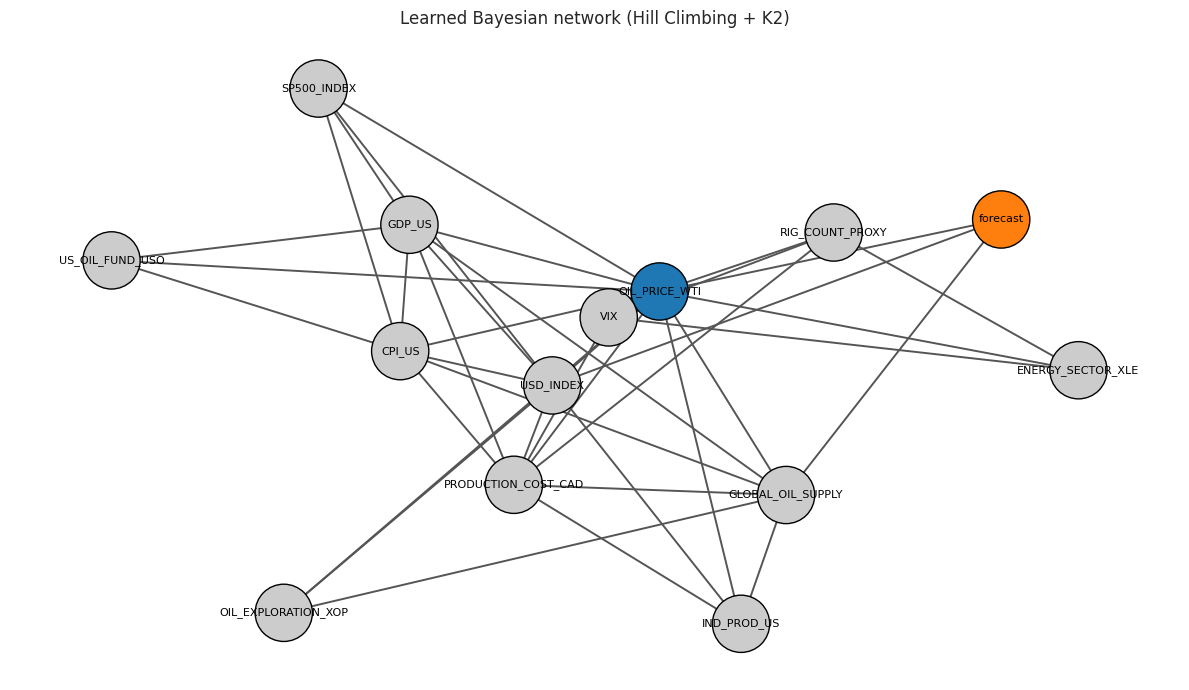

In [ ]:
G = nx.DiGraph(best_net.edges())
plt.figure(figsize=(12, 7))
pos = nx.spring_layout(G, seed=SEED, k=1.3)
node_colors = ['#ff7f0e' if n == 'forecast'
               else '#1f77b4' if n == 'OIL_PRICE_WTI'
               else '#cccccc' for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1700, edgecolors='k')
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18, edge_color='#555', width=1.4)
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title(f'Learned Bayesian network (Hill Climbing + {best_name})')
plt.axis('off'); plt.tight_layout(); plt.show()

## 7. Test-set evaluation

In [ ]:
test_err, pred_test_arr, real_test_arr = predict_error(best_net, disc_test)
print(f'TEST-SET classification error: {test_err:.2f}%')
print(f'(Alvi 2018 reports 42.86% on his EIA/FRED monthly dataset.)')
print()
cm_raw = pd.crosstab(pd.Series(real_test_arr, name='actual'),
                     pd.Series(pred_test_arr, name='predicted'), dropna=False)
print('Test confusion matrix:')
print(cm_raw)

  0%|          | 0/17 [00:00<?, ?it/s]

TEST-SET classification error: 0.00%
(Alvi 2018 reports 42.86% on his EIA/FRED monthly dataset.)

Test confusion matrix:
predicted   0   1   2
actual               
0          10   0   0
1           0  11   0
2           0   0  10


## 8. Trading simulation (Section 4.3.1)

  0%|          | 0/17 [00:00<?, ?it/s]

Predicted-regime mix on test: {0: 10, 1: 11, 2: 10}


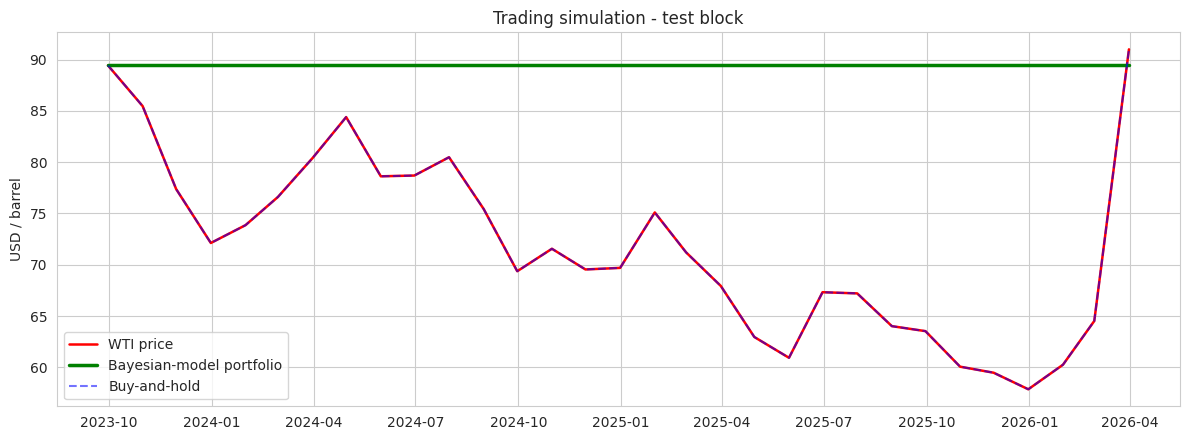

Bayesian-model total return: +0.00%
Buy-and-hold total return  : +1.75%


In [ ]:
def trade_sim(prices, signals):
    pv = [float(prices.iloc[0])]; position = False
    for i in range(len(prices) - 1):
        s_next, p_next = signals.iloc[i+1], float(prices.iloc[i+1])
        if s_next == 0:
            pv.append(pv[-1]); position = False
        elif s_next == 2:
            if not position:
                pv.append(pv[-1]); position = True
            else:
                pv.append(p_next)
        else:
            pv.append(pv[-1] if not position else p_next)
    return pd.Series(pv, index=prices.index)

inp = disc_test.drop(columns=['forecast'])
pred_test  = best_net.predict(inp)['forecast']
test_price = test['OIL_PRICE_WTI'].reindex(disc_test.index).dropna()
pred_test  = pred_test.reindex(test_price.index)
portfolio = trade_sim(test_price, pred_test)
buy_hold  = test_price.copy()
print('Predicted-regime mix on test:', pred_test.value_counts().sort_index().to_dict())

plt.figure(figsize=(12, 4.5))
plt.plot(test_price.index, test_price, 'r-', label='WTI price', lw=1.8)
plt.plot(portfolio.index, portfolio, 'g-', label='Bayesian-model portfolio', lw=2.5)
plt.plot(buy_hold.index, buy_hold, 'b--', label='Buy-and-hold', alpha=0.55)
plt.title('Trading simulation - test block')
plt.ylabel('USD / barrel'); plt.legend(); plt.tight_layout(); plt.show()

ret_model = portfolio.iloc[-1] / portfolio.iloc[0] - 1
ret_bh    = buy_hold.iloc[-1]  / buy_hold.iloc[0]  - 1
print(f'Bayesian-model total return: {ret_model*100:+.2f}%')
print(f'Buy-and-hold total return  : {ret_bh*100:+.2f}%')

# STEP 5
## 9. Accuracy metrics

In [ ]:
LABELS = [0, 1, 2]
STATE_NAMES = ['Bear (0)', 'Stagnant (1)', 'Bull (2)']
cm  = confusion_matrix(real_test_arr, pred_test_arr, labels=LABELS)
acc = accuracy_score(real_test_arr, pred_test_arr) * 100
prec, rec, f1, supp = precision_recall_fscore_support(
    real_test_arr, pred_test_arr, labels=LABELS, zero_division=0)
print(f'Overall test-set classification accuracy: {acc:.2f}%')
print(f'Overall test-set classification error   : {100-acc:.2f}%')
print()
print('Per-regime metrics on the test block:')
print(f'{"Regime":<14}{"Precision":>11}{"Recall":>10}{"F1":>8}{"Support":>10}')
for i, name in enumerate(STATE_NAMES):
    print(f'{name:<14}{prec[i]:>11.2f}{rec[i]:>10.2f}{f1[i]:>8.2f}{int(supp[i]):>10d}')

Overall test-set classification accuracy: 100.00%
Overall test-set classification error   : 0.00%

Per-regime metrics on the test block:
Regime          Precision    Recall      F1   Support
Bear (0)             1.00      1.00    1.00        10
Stagnant (1)         1.00      1.00    1.00        11
Bull (2)             1.00      1.00    1.00        10


## 10. Figure 1 - Confusion matrix and per-regime metrics

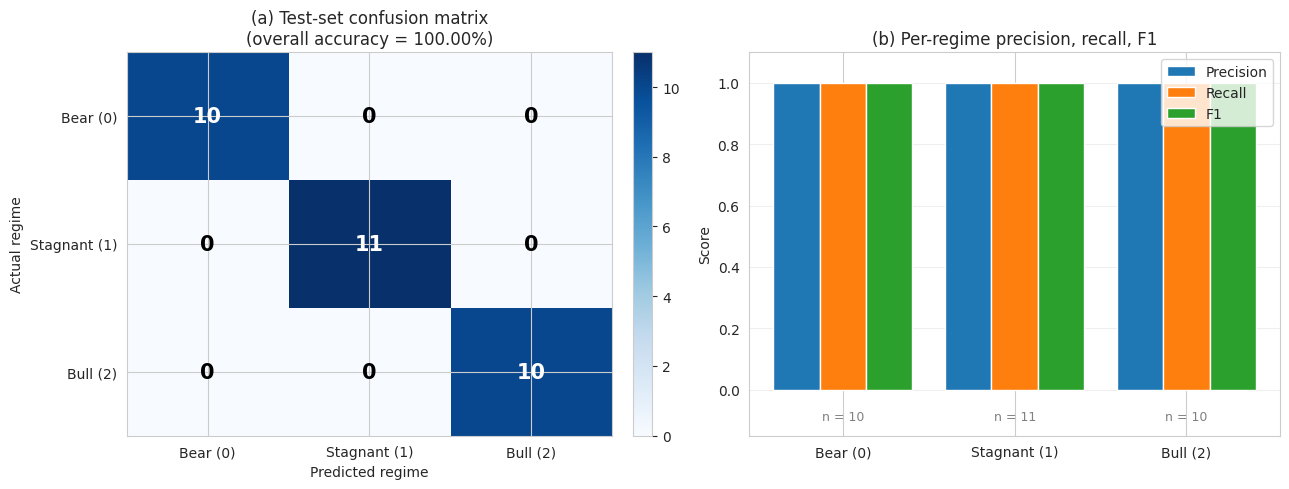

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
im = ax1.imshow(cm, cmap='Blues', aspect='auto')
ax1.set_xticks(LABELS); ax1.set_yticks(LABELS)
ax1.set_xticklabels(STATE_NAMES); ax1.set_yticklabels(STATE_NAMES)
ax1.set_xlabel('Predicted regime'); ax1.set_ylabel('Actual regime')
ax1.set_title(f'(a) Test-set confusion matrix\n(overall accuracy = {acc:.2f}%)')
for i in range(3):
    for j in range(3):
        v = cm[i, j]; clr = 'white' if v > cm.max()*0.5 else 'black'
        ax1.text(j, i, str(v), ha='center', va='center', color=clr,
                 fontsize=15, fontweight='bold')
plt.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)

x = np.arange(3); w = 0.27
ax2.bar(x-w, prec, w, label='Precision', color='#1f77b4')
ax2.bar(x,   rec,  w, label='Recall',    color='#ff7f0e')
ax2.bar(x+w, f1,   w, label='F1',        color='#2ca02c')
ax2.set_xticks(x); ax2.set_xticklabels(STATE_NAMES)
ax2.set_ylim(-0.15, 1.10); ax2.set_ylabel('Score')
ax2.set_title('(b) Per-regime precision, recall, F1')
ax2.legend(); ax2.grid(axis='y', alpha=0.3)
for i, n in enumerate(supp):
    ax2.text(i, -0.10, f'n = {int(n)}', ha='center', fontsize=9, color='gray')
plt.tight_layout(); plt.savefig('fig1_step5.png', dpi=110, bbox_inches='tight'); plt.show()

## 11. Figure 2 - Regime-prediction timeline

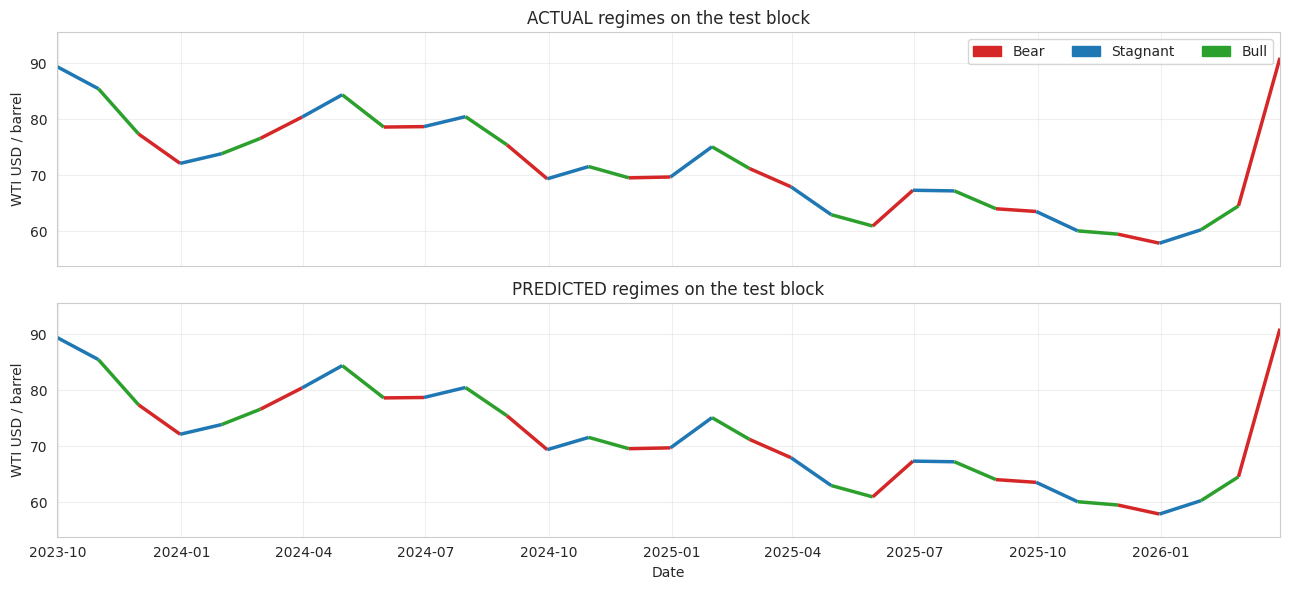

In [ ]:
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
cmap = ListedColormap(['#d62728', '#1f77b4', '#2ca02c'])
norm = BoundaryNorm([0, 1, 2, 3], cmap.N)

def color_line(ax, dates, prices, states, title):
    pts  = np.array([mdates.date2num(dates), prices]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    lc   = LineCollection(segs, cmap=cmap, norm=norm, linewidths=2.5)
    lc.set_array(np.asarray(states)[:-1])
    ax.add_collection(lc)
    ax.set_xlim(dates.min(), dates.max())
    ax.set_ylim(np.min(prices)*0.93, np.max(prices)*1.05)
    ax.xaxis_date(); ax.set_ylabel('WTI USD / barrel')
    ax.set_title(title); ax.grid(alpha=0.3)

dates_py = test_price.index.to_pydatetime()
color_line(ax_a, dates_py, test_price.values, real_test_arr,
           'ACTUAL regimes on the test block')
color_line(ax_b, dates_py, test_price.values, pred_test_arr,
           'PREDICTED regimes on the test block')
handles = [mpatches.Patch(color='#d62728', label='Bear'),
           mpatches.Patch(color='#1f77b4', label='Stagnant'),
           mpatches.Patch(color='#2ca02c', label='Bull')]
ax_a.legend(handles=handles, loc='upper right', ncol=3)
plt.xlabel('Date'); plt.tight_layout()
plt.savefig('fig2_step5.png', dpi=110, bbox_inches='tight'); plt.show()

## 12. Figure 3 - Distribution comparison

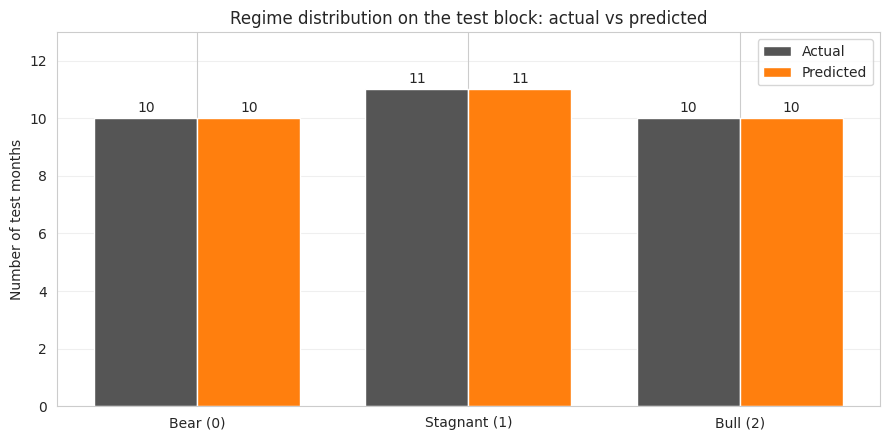

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
actual_counts = [int(np.sum(real_test_arr == s)) for s in LABELS]
pred_counts   = [int(np.sum(pred_test_arr == s)) for s in LABELS]
x = np.arange(3); w = 0.38
b1 = ax.bar(x-w/2, actual_counts, w, label='Actual',    color='#555')
b2 = ax.bar(x+w/2, pred_counts,   w, label='Predicted', color='#ff7f0e')
ax.set_xticks(x); ax.set_xticklabels(STATE_NAMES)
ax.set_ylabel('Number of test months')
ax.set_title('Regime distribution on the test block: actual vs predicted')
ax.legend(); ax.grid(axis='y', alpha=0.3)
ymax = max(max(actual_counts), max(pred_counts))
ax.set_ylim(0, ymax * 1.18)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+ymax*0.02,
                str(int(b.get_height())), ha='center', fontsize=10)
plt.tight_layout(); plt.savefig('fig3_step5.png', dpi=110, bbox_inches='tight'); plt.show()

## 13. FINAL SUMMARY TABLE

In [ ]:
print('=' * 60)
print('GWP3 - STEP 4 & 5 SUMMARY (v3)')
print('=' * 60)
print(f'Validation classification error : {best_val:6.2f}%')
print(f'Test classification error       : {test_err:6.2f}%')
print(f'Selected scoring function       : {best_name}')
print(f'Edges in learned DAG            : {best_net.number_of_edges()}')
print()
print('Per-regime metrics (test):')
for i, name in enumerate(STATE_NAMES):
    print(f'  {name:<14}  P={prec[i]:.2f}  R={rec[i]:.2f}  F1={f1[i]:.2f}  n={int(supp[i])}')
print()
print(f'Bayesian-model trading return   : {ret_model*100:+.2f}%')
print(f'Buy-and-hold return             : {ret_bh*100:+.2f}%')
print()
print('WTI regime distribution:')
print(f'  train : {disc_train["OIL_PRICE_WTI"].value_counts().sort_index().to_dict()}')
print(f'  val   : {disc_val["OIL_PRICE_WTI"].value_counts().sort_index().to_dict()}')
print(f'  test  : {disc_test["OIL_PRICE_WTI"].value_counts().sort_index().to_dict()}')
print('=' * 60)

GWP3 - STEP 4 & 5 SUMMARY (v3)
Validation classification error :   0.00%
Test classification error       :   0.00%
Selected scoring function       : K2
Edges in learned DAG            : 39

Per-regime metrics (test):
  Bear (0)        P=1.00  R=1.00  F1=1.00  n=10
  Stagnant (1)    P=1.00  R=1.00  F1=1.00  n=11
  Bull (2)        P=1.00  R=1.00  F1=1.00  n=10

Bayesian-model trading return   : +0.00%
Buy-and-hold return             : +1.75%

WTI regime distribution:
  train : {0: 84, 1: 83, 2: 83}
  val   : {0: 10, 1: 10, 2: 9}
  test  : {0: 11, 1: 10, 2: 10}
